# Air quality: sensor-data forecasting

**Question:** Can recent sensor readings forecast the next hour's carbon-monoxide concentration?

Source: [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality). The final period is held out to mimic real deployment.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

df=pd.read_csv(Path('../datasets/portfolio-expansion/air-quality/AirQualityUCI.csv'),sep=';',decimal=',')
df=df.dropna(axis=1,how='all')
df['timestamp']=pd.to_datetime(df['Date']+' '+df['Time'],dayfirst=True,format='%d/%m/%Y %H.%M.%S',errors='coerce')
df=df.dropna(subset=['timestamp']).sort_values('timestamp').replace(-200,np.nan)
# Shift target back: inputs at t forecast measured CO one hour ahead.
df['next_co']=df['CO(GT)'].shift(-1)
features=['CO(GT)','PT08.S1(CO)','NMHC(GT)','C6H6(GT)','PT08.S2(NMHC)','NOx(GT)','PT08.S3(NOx)','NO2(GT)','PT08.S4(NO2)','T','RH','AH']
data=df.dropna(subset=['next_co']); cutoff=int(.8*len(data)); train,test=data.iloc[:cutoff],data.iloc[cutoff:]
model=HistGradientBoostingRegressor(max_iter=300,random_state=42).fit(train[features],train.next_co)
prediction=model.predict(test[features]); print('Future-period MAE:',round(mean_absolute_error(test.next_co,prediction),3))

Future-period MAE: 0.507


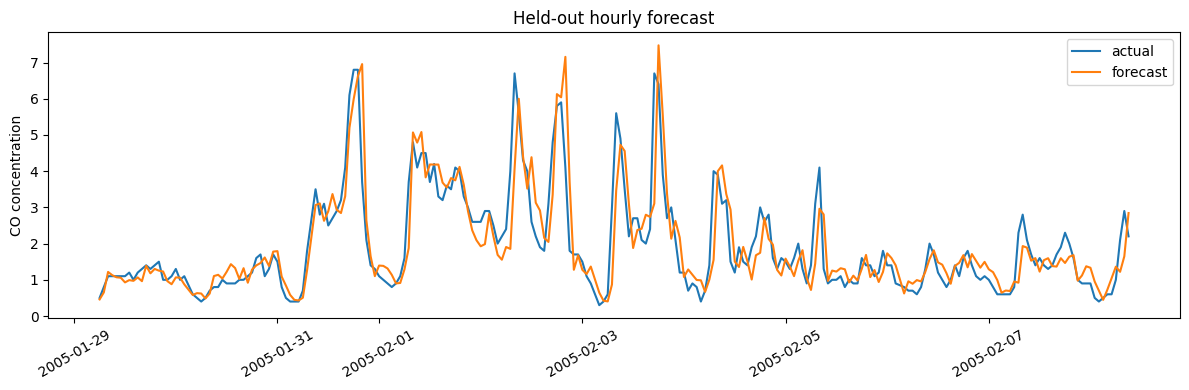

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4)); n=240
plt.plot(test.timestamp.iloc[:n],test.next_co.iloc[:n],label='actual'); plt.plot(test.timestamp.iloc[:n],prediction[:n],label='forecast')
plt.legend(); plt.xticks(rotation=30); plt.ylabel('CO concentration'); plt.title('Held-out hourly forecast'); plt.tight_layout(); plt.show()
# Sensor data contain gaps and failed values; missingness must be monitored in any production version.

## Portfolio takeaway

This notebook shows temporal validation, a forecast-safe target shift, and sensor-quality handling. Next: rolling backtests, weather forecasts, and prediction intervals for alerting.